# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
from time import time
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *
from sources.finitevolume import *

2022-09-07 12:01:01.015912: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:936] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-09-07 12:01:01.033148: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudnn.so.8'; dlerror: libcudnn.so.8: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/run/user/1000/doc:/run/user/1000/doc
2022-09-07 12:01:01.033163: W tensorflow/core/common_runtime/gpu/gpu_device.cc:1850] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
2022-09-07 12:01:01.033616: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is 

# Generate data

In [10]:
# Set boundary
tmin = 0.
tmax = 1.
xmin = -1.
xmax = 1.

# Lower bounds
lb = tf.constant([tmin, xmin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax], dtype=DTYPE)

In [11]:
X_r, X_data, u_data = gen_train_data(lb, ub, nu = False, N_r = 10_000, N_0 = 1_000,N_b = 1_000)

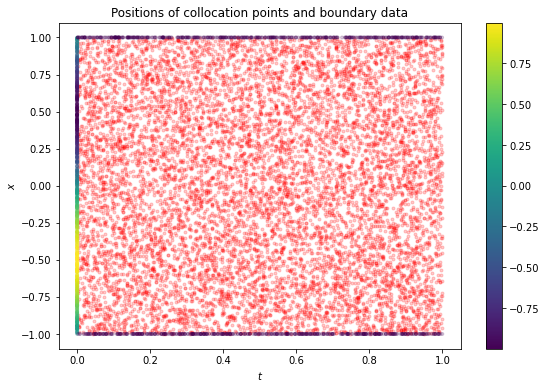

In [12]:
plot_train_data(X_r, X_data, u_data)

# Training

In [13]:
model = PhysicsInformedNN(lb, ub, output_dim=1, num_hidden_layers=8, num_neurons_per_layer=20, activation='tanh')
model.build(input_shape=(None,2))

solver = PINNSolver(model, batch_size = 5_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=100,
    decay_rate=0.98,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r, X_data, u_data, alpha = 1.)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 12_400: phi_r  1.0063e-03    phi_0  1.1989e-05    phi_b  1.1390e-04    total_loss  1.1322e-03
Training time: 522.2647640705109 seconds


<AxesSubplot:xlabel='Iteration', ylabel='Loss'>

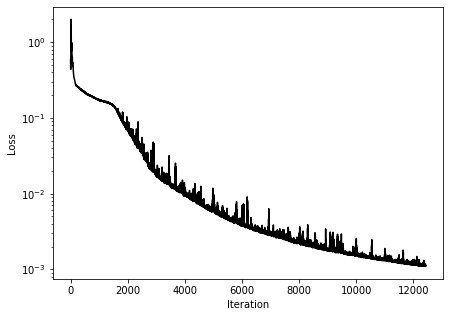

In [14]:
solver.plot_loss_history()

# Check results

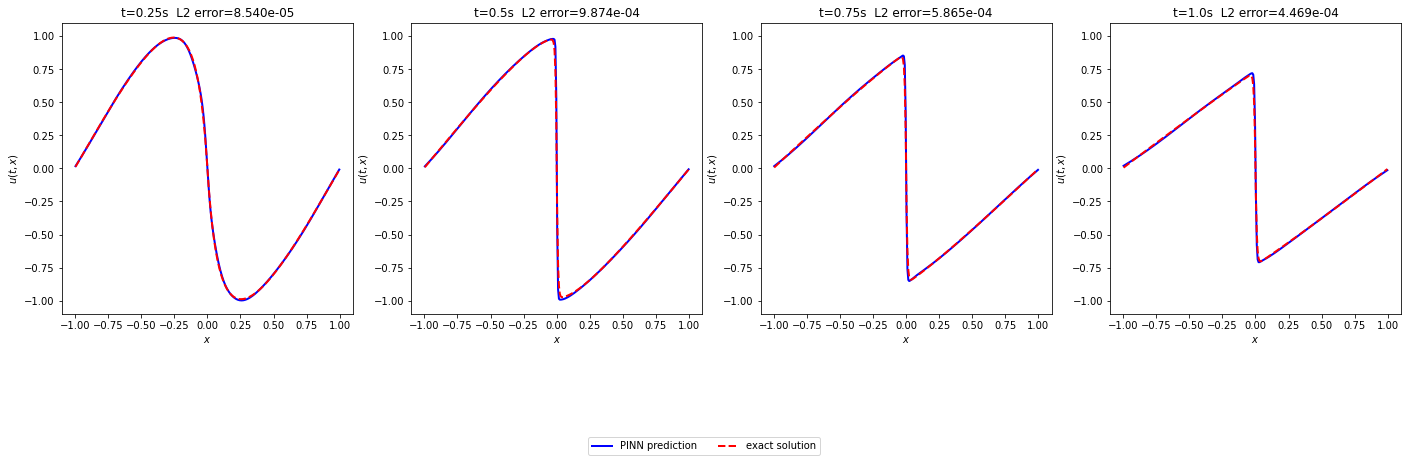

In [15]:
all_times = [0.25, 0.5, 0.75, 1.0]
exact_solutions = []
N = 300

# initialize exact solver
bg=EDP(N, viscosity.numpy() , u_0)
x = bg.cells[bg.begin:bg.end]

# compute exact solution 
for i_t, end_time in enumerate(all_times):
  bg.init()
  sol=bg.solve(end_time)
  exact_solutions.append(sol[-1])

fig, ax = plt.subplots(1, 4, figsize=(24, 8))

for i_t, end_time in enumerate(all_times):

    exact_sol = exact_solutions[i_t]

    # PINN prediction
    T, X = np.meshgrid(end_time, x)
    Xgrid = np.vstack([T.flatten(),X.flatten()]).T
    upred = model(tf.cast(Xgrid,DTYPE))
    upred = tf.reshape(upred, (1,N))[0].numpy()

    # plot 
    erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
    title = "t={}s  L2 error={:5.3e}".format(end_time, erreurL2)
    ax[i_t].set_title(title)

    ax[i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
    ax[i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

    ax[i_t].set_xlabel('$x$')
    ax[i_t].set_ylabel('$u(t,x)$')    
    ax[i_t].axis('square')
    ax[i_t].set_xlim([-1.1,1.1])
    ax[i_t].set_ylim([-1.1,1.1]);

handles, labels = ax[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2);